# From an Interconnect graph to a shaped invariant measure

Algorithm 2 of *Shaping of invariant measures of parametrized stochastic dynamical systems* (Shafiei, Mareček, Shorten) needs to know, for each response mode of the agent, how much one step of the loop can stretch distances between states. Here the loop contains a neural-network controller and a nonlinear filter, so this cannot be read off a formula. The notebook gets it from Interconnect, by running the graph:

1. `ControlSystem.run()` starts the loop from chosen states and runs it under a law $\mu$ of the agent's modes;
2. at the states the runs visit, `get_jacobian_norm` differentiates one `run()` pass for each mode;
3. these slopes give the contraction-on-average constant $C(\mu)$ of the Interconnect paper, eq. (12), and the Lipschitz constants $L_i$ of the shaping paper, for every $\mu$ at once, and with them the search region $\mathcal A_r$;
4. Algorithm 2 shapes the loop's invariant measure inside $\mathcal A_r$, and the graph is run under the result.

In [1]:
import os, sys
ROOT = os.path.abspath("../..")
for p in [ROOT, os.getcwd()]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy import stats

from ims_core import proj_Ar, simplex_grid
from opaque_system import OpaqueSim, grid_chain
from regions import (lipschitz_constants, average_lipschitz, contraction_on_average,
                     nondominated_rows, proj_Cr, projected_subgradient)
from shaping_system import empirical_measure

BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
LIGHT_BLUE, DARK_BLUE = "#b7d3f6", "#256abf"
COLORS = [BLUE, ORANGE, AQUA]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.titlesize": 11, "font.size": 10,
                     "lines.linewidth": 2})

## 1. The loop

`r → A1 → F → C → P1 → A1`, with the reference $r=0.5$:

- `A1` forms the error $e=r-y$ from the agent's last answer $y$;
- `F` distorts it nonlinearly, $F(e)=e-0.05\sin 2\pi e$;
- `C` is a network $u=W_2\tanh(W_1F(e)+b_1)$ with 16 hidden units and fixed random weights;
- `P1` is one agent that draws a response mode with law $\mu$ at every step and answers $y_{t+1}=\sigma(c_i+s_iu_t)\in(0,1)$:
  - **calm** pulls the answer towards $0.5$;
  - **polarise low** pushes it away from $0.25$;
  - **polarise high** pushes it away from $0.75$.

The state is the agent's answer $y_t$, the output of `P1`. `A1` reads it at the start of every pass, so it is exactly what `run()` carries from one pass to the next.

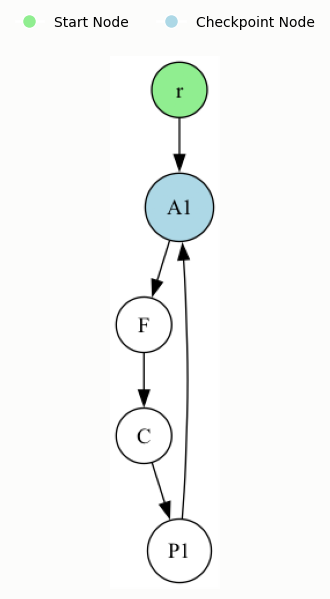

In [2]:
sim = OpaqueSim()
names = sim.mode_names
sim.plot.render_graph()

## 2. Running the graph from a chosen state

`run(iterations, initial_outputs={"P1": y0})` lets `P1` hold the answer $y_0$ before the first pass, so the first error is $r-y_0$. `sim.simulate(mu, T, x0)` runs the graph this way under the law $\mu$.

One pass from a state $y$ with the agent forced to mode $i$ is `run(1)` from $y$; this is the map $w_i(y)$, `sim.step(y, i)`. The left plot shows runs from five starting answers under the uniform law. The right plot shows the three maps, each computed with one `run(1)` from a whole batch of states; where a map crosses the dotted diagonal, the answer would stay where it is under that mode.

max |y_(t+1) - w_i(y_t)| over 3000 steps: 0.0e+00


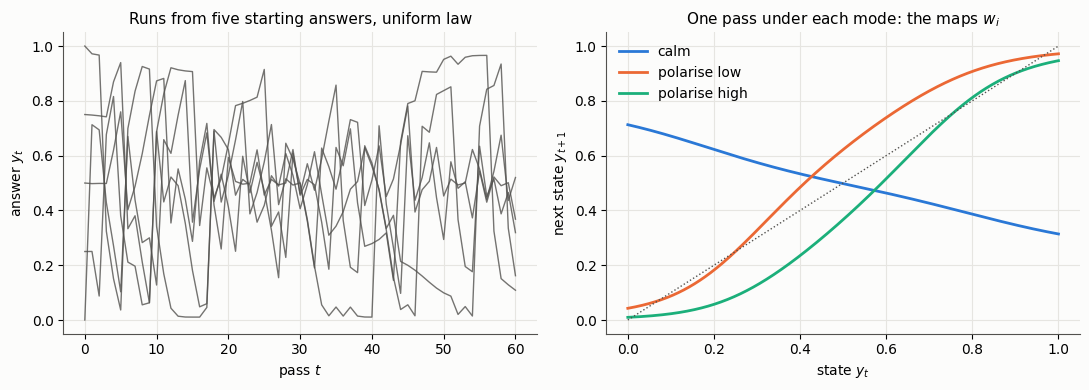

In [3]:
mu_explore = np.ones(3) / 3
starts = [0.0, 0.25, 0.5, 0.75, 1.0]

path, modes = sim.simulate(mu_explore, 3000, x0=0.0, seed=1)
pred = np.array([float(sim.step(torch.tensor([y]), int(i))) for i, y in zip(modes, path[:-1])])
print(f"max |y_(t+1) - w_i(y_t)| over 3000 steps: {np.abs(pred - path[1:]).max():.1e}")
assert np.abs(pred - path[1:]).max() < 1e-12

x = np.linspace(0, 1, 801)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, y0 in enumerate(starts):
    axes[0].plot(sim.simulate(mu_explore, 60, x0=y0, seed=1 + k)[0], color=MUTED, lw=1, alpha=0.8)
axes[0].set(xlabel="pass $t$", ylabel="answer $y_t$", title="Runs from five starting answers, uniform law")
for wi, name, c in zip(sim.maps(x), names, COLORS):
    axes[1].plot(x, wi, color=c, label=name)
axes[1].plot(x, x, color=MUTED, lw=1, ls=":")
axes[1].set(xlabel="state $y_t$", ylabel="next state $y_{t+1}$", title="One pass under each mode: the maps $w_i$")
axes[1].legend(frameon=False)
fig.tight_layout(); plt.show()

## 3. Contraction on average from the runs

For a one-dimensional state, eq. (12) of the Interconnect paper reads

$$C(\mu)=\sup_y\sum_i\mu_i\,|w_i'(y)| .$$

The runs from the five starts visit a set of states. At each visited state $y_j$, `sim.slopes` differentiates one `run(1)` pass for each mode with `get_jacobian_norm`, which gives a table $D[j,i]=|w_i'(y_j)|$: one row per visited state, one column per mode. The law $\mu$ only weights the columns, so the same table serves every $\mu$:

- $C(\mu)=\max_j\,(D\mu)_j$: average over modes at each state, then the worst state (eq. (12));
- $L_i=\max_j D[j,i]$ and $L(\mu)=\sum_i\mu_iL_i$: the worst state for each mode, then the average (the shaping paper).

Both are maxima over the visited states, so they are estimates from below.

2005 visited states
calm           L_i = 0.4978  at y = 0.184
polarise low   L_i = 1.6010  at y = 0.322
polarise high  L_i = 1.6002  at y = 0.647
mu = [0.4 0.3 0.3]:  L(mu) = 1.1595,  C(mu) = 0.9674


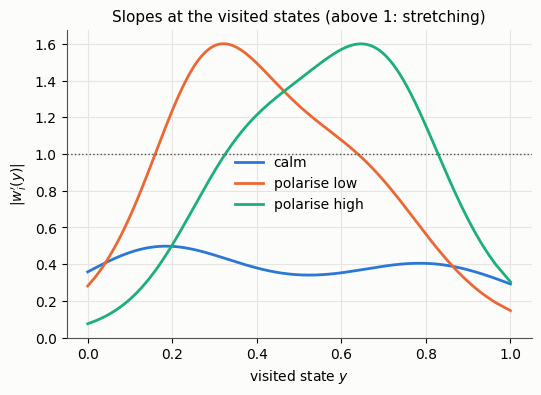

In [4]:
states = np.concatenate([sim.simulate(mu_explore, 400, x0=y0, seed=20 + k)[0] for k, y0 in enumerate(starts)])
D = sim.slopes(states)
ell = lipschitz_constants(D)
print(f"{len(states)} visited states")
for name, l, j in zip(names, ell, D.argmax(axis=0)):
    print(f"{name:<14} L_i = {l:.4f}  at y = {states[j]:.3f}")
mu_test = np.array([0.4, 0.3, 0.3])
print(f"mu = {mu_test}:  L(mu) = {average_lipschitz(mu_test, D):.4f},  C(mu) = {contraction_on_average(mu_test, D):.4f}")

order = np.argsort(states)
fig, ax = plt.subplots(figsize=(6, 4))
for i, (name, c) in enumerate(zip(names, COLORS)):
    ax.plot(states[order], D[order, i], color=c, label=name)
ax.axhline(1.0, color=MUTED, lw=1, ls=":")
ax.set(xlabel="visited state $y$", ylabel="$|w_i'(y)|$", title="Slopes at the visited states (above 1: stretching)")
ax.legend(frameon=False)
plt.show()

## 4. Check against the whole state space

Because the state is one-dimensional, the run-based estimates can be compared with the same quantities on a fine grid of all states, and the autograd slopes with finite differences.

In [5]:
xg = np.linspace(0, 1, 2001)
Dg = sim.slopes(xg)
print("L_i from runs:", np.round(ell, 4))
print("L_i on grid  :", np.round(lipschitz_constants(Dg), 4))
for mu in [mu_test, np.array([0.6, 0.2, 0.2]), np.array([0.2, 0.4, 0.4])]:
    print(f"C({mu}): runs {contraction_on_average(mu, D):.4f}, grid {contraction_on_average(mu, Dg):.4f}")

h = 1e-6
fd = np.abs(sim.maps(xg[1:-1] + h) - sim.maps(xg[1:-1] - h)).T / (2 * h)
gap = np.abs(Dg[1:-1] - fd).max()
print(f"max |get_jacobian_norm - finite difference| = {gap:.1e}")
assert gap < 1e-6

L_i from runs: [0.4978 1.601  1.6002]
L_i on grid  : [0.4978 1.601  1.6002]
C([0.4 0.3 0.3]): runs 0.9674, grid 0.9674
C([0.6 0.2 0.2]): runs 0.7807, grid 0.7807
C([0.2 0.4 0.4]): runs 1.1595, grid 1.1595
max |get_jacobian_norm - finite difference| = 6.9e-10


## 5. The search region $\mathcal A_r$

With $r=0.9$, two regions follow from the same table $D$:

- $\mathcal A_r^L=\{\mu: L(\mu)\le r\}$, the region of the shaping paper;
- $\mathcal A_r^C=\{\mu: C(\mu)\le r\}$, with the constant of eq. (12). It contains $\mathcal A_r^L$, because $C(\mu)\le L(\mu)$. Using it in Algorithm 2 is our extension and is not part of the shaping paper.

Each point of the triangle is a law $\mu$; a corner is a law that always uses that mode.

A_r^L covers 13% of the simplex, A_r^C covers 23%


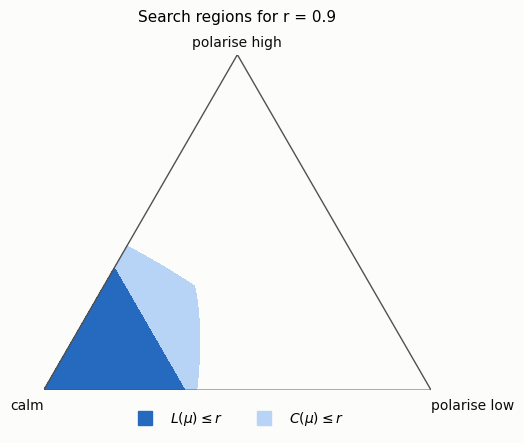

In [6]:
r = 0.9
D_active = nondominated_rows(D)   # rows that can bound C(mu); the others never do
P_L = lambda y: proj_Ar(y, ell, r)
P_C = lambda y: proj_Cr(y, D_active, r)

def to_xy(m):
    m = np.atleast_2d(m)
    return m[:, 1] + 0.5 * m[:, 2], np.sqrt(3) / 2 * m[:, 2]

G = simplex_grid(3, 200)
gx, gy = to_xy(G)
tri = mtri.Triangulation(gx, gy)
L_grid = G @ ell
C_grid = (D_active @ G.T).max(axis=0)

def draw_simplex(ax):
    ax.tricontourf(tri, C_grid, levels=[0, r], colors=[LIGHT_BLUE])
    ax.tricontourf(tri, L_grid, levels=[0, r], colors=[DARK_BLUE])
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3) / 2, 0], color=MUTED, lw=1)
    for (cx, cy), name, ha in zip([(0, 0), (1, 0), (0.5, np.sqrt(3) / 2)], names, ["right", "left", "center"]):
        ax.annotate(name, (cx, cy), xytext=(0, -14 if cy == 0 else 6), textcoords="offset points", ha=ha, color=INK)
    ax.plot([], [], "s", color=DARK_BLUE, ms=10, label="$L(\\mu)\\leq r$")
    ax.plot([], [], "s", color=LIGHT_BLUE, ms=10, label="$C(\\mu)\\leq r$")
    ax.set_aspect("equal"); ax.axis("off")

print(f"A_r^L covers {np.mean(L_grid <= r):.0%} of the simplex, A_r^C covers {np.mean(C_grid <= r):.0%}")
fig, ax = plt.subplots(figsize=(5, 4.5))
draw_simplex(ax)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.02))
ax.set_title(f"Search regions for r = {r}", pad=24)
plt.show()

## 6. Algorithm 2

Algorithm 2 computes the invariant measure $\pi_\mu$ and the gradient of $J(\mu)=W_1(\nu,\pi_\mu)$ on a finite-state model of the loop: the interval $[0,1]$ split into 801 points, each map tabulated with one batched `run(1)` pass from all of them.

### 6.1 Gradient check

The sensitivity formula of the paper against central finite differences of $J$, at a law inside $\mathcal A_r^L$.

In [7]:
chain = grid_chain(sim.maps(x), x)

mu = np.array([0.75, 0.12, 0.13])
nu = chain.stationary(np.array([0.80, 0.08, 0.12]))
p = chain.stationary(mu)
g = chain.sensitivity(mu, p, chain.potential(p, nu))
worst = 0.0
for d in [np.array([1., -1, 0]), np.array([1., 0, -1]), np.array([0., 1, -1])]:
    fd = (chain.w1(chain.stationary(mu + 1e-6 * d), nu) - chain.w1(chain.stationary(mu - 1e-6 * d), nu)) / 2e-6
    worst = max(worst, abs(fd - g @ d))
    print(f"direction {d}: finite difference {fd:+.5f}, formula {g @ d:+.5f}")
assert worst < 1e-4

direction [ 1. -1.  0.]: finite difference -0.19664, formula -0.19664
direction [ 1.  0. -1.]: finite difference -0.23620, formula -0.23620
direction [ 0.  1. -1.]: finite difference -0.03956, formula -0.03956


### 6.2 Experiment A: a target the loop can reach

Plant $\mu^\star$ inside $\mathcal A_r^L$, take $\nu=\pi_{\mu^\star}$ as the target, and recover $\mu^\star$ with Polyak steps from the projected uniform law. Then run the graph under the recovered law from $y_0=0$ and $y_0=1$.

L(mu*) = 0.774 <= r = 0.9


planted mu*: [0.75 0.1  0.15]
start mu0  : [0.6353 0.1822 0.1825]  J = 0.0258
recovered  : [0.75 0.1  0.15]  J = 4.9e-14


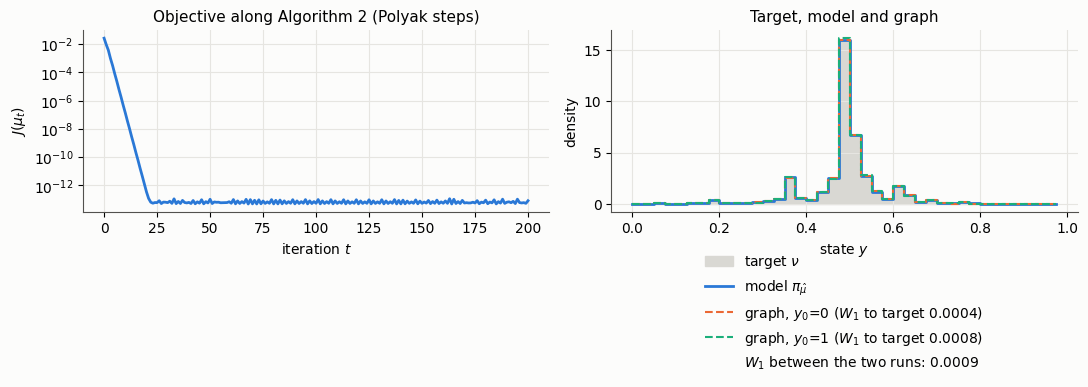

In [8]:
def bins(p, width=20):
    k = len(p) // width
    q = np.add.reduceat(p, np.arange(0, width * k, width))
    edges = x[np.arange(0, width * k, width)]
    return edges, q / (edges[1] - edges[0])

def plot_measures(ax, target, mu_hat, x0s=(0.0, 1.0), steps=60000, seed=3, burn=500):
    edges, d = bins(target); ax.fill_between(edges, d, step="post", color="#d9d8d3", label="target $\\nu$")
    edges, d = bins(chain.stationary(mu_hat)); ax.step(edges, d, where="post", color=BLUE, label="model $\\pi_{\\hat\\mu}$")
    # Runs the real graph under mu_hat from each x0; the legend gives each run's W1 distance to the target.
    emps = []
    for k, (x0, c) in enumerate(zip(x0s, [ORANGE, AQUA])):
        path, _ = sim.simulate(mu_hat, steps, x0=x0, seed=seed + k)
        emps.append(empirical_measure(path[burn:], x))
        edges, d = bins(emps[-1])
        ax.step(edges, d, where="post", color=c, lw=1.5, ls="--",
                label=f"graph, $y_0$={x0:g} ($W_1$ to target {chain.w1(emps[-1], target):.4f})")
    ax.plot([], [], " ", label=f"$W_1$ between the two runs: {chain.w1(emps[0], emps[1]):.4f}")
    ax.set(xlabel="state $y$", ylabel="density")
    ax.legend(frameon=False, ncol=1, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    return emps

mu_star = np.array([0.75, 0.10, 0.15])
print(f"L(mu*) = {average_lipschitz(mu_star, D):.3f} <= r = {r}")
nu_A = chain.stationary(mu_star)
mu0 = P_L(np.ones(3) / 3)
res_A = projected_subgradient(chain, nu_A, mu0, 200, P_L, step="polyak")
print("planted mu*:", mu_star)
print("start mu0  :", np.round(mu0, 4), f" J = {res_A['J'][0]:.4f}")
print("recovered  :", np.round(res_A["best_mu"], 6), f" J = {res_A['best_J']:.1e}")
assert np.abs(res_A["best_mu"] - mu_star).max() < 1e-6

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].semilogy(res_A["J"], color=BLUE)
axes[0].set(xlabel="iteration $t$", ylabel="$J(\\mu_t)$", title="Objective along Algorithm 2 (Polyak steps)")
emps_A = plot_measures(axes[1], nu_A, res_A["best_mu"]); axes[1].set_title("Target, model and graph")
fig.tight_layout(); plt.show()
assert max(chain.w1(e, nu_A) for e in emps_A) < 0.01

### 6.3 Experiment B: a target the loop cannot reach exactly

Target $\mathrm{Beta}(10,10)$. Algorithm 2 runs from three starts with diminishing steps, and a grid search over $\mathcal A_r^L$ serves as an independent reference.

grid search over A_r^L (2701 laws): mu = [0.64  0.185 0.175],  J = 0.02738


Algorithm 2 from [0.33 0.33 0.33]: mu = [0.6353 0.1899 0.1748],  J = 0.02703,  L(mu) = 0.900


Algorithm 2 from [0.9 0.1 0. ]: mu = [0.6353 0.1899 0.1748],  J = 0.02703,  L(mu) = 0.900


Algorithm 2 from [0.9 0.  0.1]: mu = [0.6353 0.1899 0.1748],  J = 0.02703,  L(mu) = 0.900


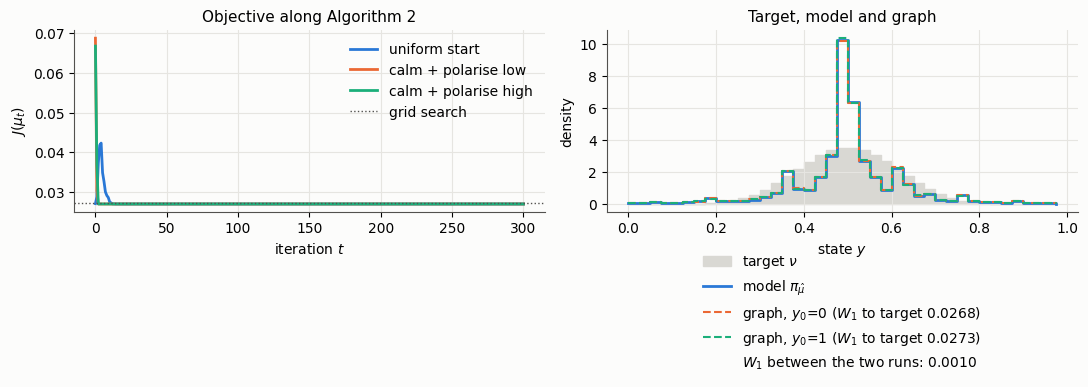

In [9]:
def beta_target(a, b):
    e = np.concatenate([[0], (x[:-1] + x[1:]) / 2, [1]])
    p = np.diff(stats.beta(a, b).cdf(e))
    return p / p.sum()

nu_B = beta_target(10, 10)
G_L = G[L_grid <= r + 1e-12]
vals_B = np.array([chain.w1(chain.stationary(m), nu_B) for m in G_L])
print(f"grid search over A_r^L ({len(G_L)} laws): mu = {np.round(G_L[vals_B.argmin()], 3)},  J = {vals_B.min():.5f}")

runs_B = []
for s in [np.ones(3) / 3, np.array([0.9, 0.1, 0.0]), np.array([0.9, 0.0, 0.1])]:
    res = projected_subgradient(chain, nu_B, P_L(s), 300, P_L, gamma=0.3)
    runs_B.append(res)
    print(f"Algorithm 2 from {s.round(2)}: mu = {np.round(res['best_mu'], 4)},  J = {res['best_J']:.5f},  "
          f"L(mu) = {average_lipschitz(res['best_mu'], D):.3f}")
best_B = min(runs_B, key=lambda res: res["best_J"])
assert best_B["best_J"] <= vals_B.min() + 1e-3

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for res, c, lab in zip(runs_B, COLORS, ["uniform start", "calm + polarise low", "calm + polarise high"]):
    axes[0].plot(res["J"], color=c, label=lab)
axes[0].axhline(vals_B.min(), color=MUTED, lw=1, ls=":", label="grid search")
axes[0].set(xlabel="iteration $t$", ylabel="$J(\\mu_t)$", title="Objective along Algorithm 2")
axes[0].legend(frameon=False)
emps_B = plot_measures(axes[1], nu_B, best_B["best_mu"]); axes[1].set_title("Target, model and graph")
fig.tight_layout(); plt.show()

### 6.4 Experiment C: the same target on $\mathcal A_r^L$ and on $\mathcal A_r^C$

Target $\mathrm{Beta}(4,4)$. Algorithm 2 runs once with each projection; a grid search over $\mathcal A_r^C$ serves as reference, and the graph is run under the result found in $\mathcal A_r^C$.

best law in A_r^L: mu = [0.635 0.082 0.282],  J = 0.0604,  L(mu) = 0.900,  C(mu) = 0.768
best law in A_r^C: mu = [0.465 0.253 0.282],  J = 0.0314,  L(mu) = 1.088,  C(mu) = 0.900
grid search over A_r^C (1165 laws): J = 0.0320
C of the A_r^C result on the 2001-point grid: 0.9000


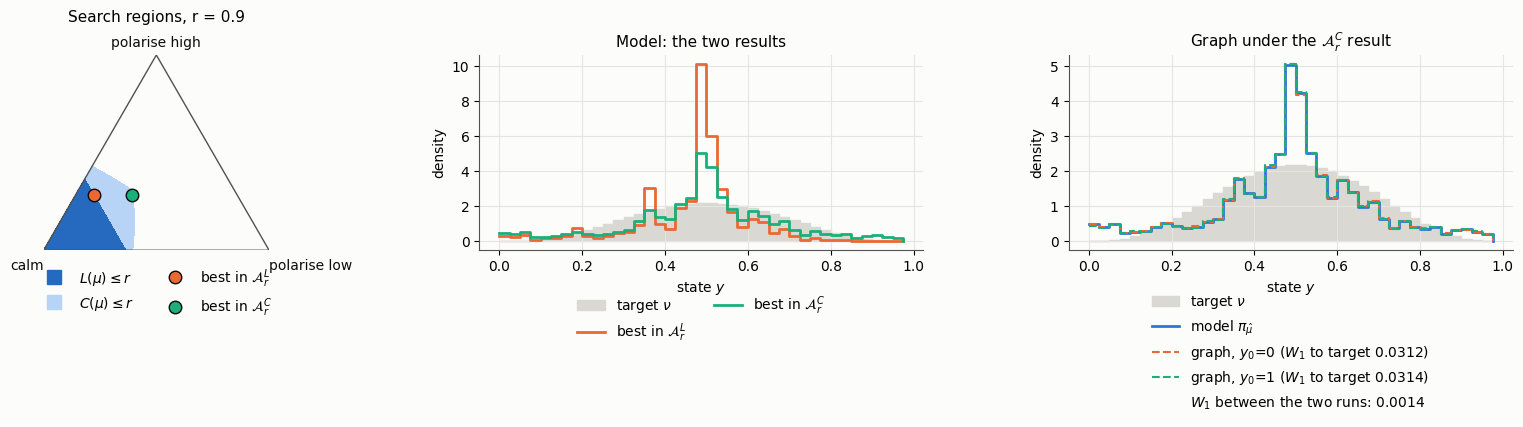

In [10]:
nu_C = beta_target(4, 4)
res_L = projected_subgradient(chain, nu_C, P_L(np.ones(3) / 3), 300, P_L, gamma=0.3)
res_C = projected_subgradient(chain, nu_C, P_C(np.ones(3) / 3), 300, P_C, gamma=0.3)
G_C = G[C_grid <= r + 1e-12][::4]
vals_C = np.array([chain.w1(chain.stationary(m), nu_C) for m in G_C])

for label, res in [("A_r^L", res_L), ("A_r^C", res_C)]:
    m = res["best_mu"]
    print(f"best law in {label}: mu = {np.round(m, 3)},  J = {res['best_J']:.4f},  "
          f"L(mu) = {average_lipschitz(m, D):.3f},  C(mu) = {contraction_on_average(m, D):.3f}")
print(f"grid search over A_r^C ({len(G_C)} laws): J = {vals_C.min():.4f}")
print(f"C of the A_r^C result on the 2001-point grid: {contraction_on_average(res_C['best_mu'], Dg):.4f}")
assert res_C["best_J"] <= vals_C.min() + 1e-3

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
ax = axes[0]
draw_simplex(ax)
for res, c, lab in [(res_L, ORANGE, "best in $\\mathcal{A}_r^L$"), (res_C, AQUA, "best in $\\mathcal{A}_r^C$")]:
    tx, ty = to_xy(res["best_mu"]); ax.plot(tx, ty, "o", color=c, mec=INK, ms=9, label=lab)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.02))
ax.set_title(f"Search regions, r = {r}", pad=24)

edges, d = bins(nu_C); axes[1].fill_between(edges, d, step="post", color="#d9d8d3", label="target $\\nu$")
edges, d = bins(chain.stationary(res_L["best_mu"])); axes[1].step(edges, d, where="post", color=ORANGE, label="best in $\\mathcal{A}_r^L$")
edges, d = bins(chain.stationary(res_C["best_mu"])); axes[1].step(edges, d, where="post", color=AQUA, label="best in $\\mathcal{A}_r^C$")
axes[1].set(xlabel="state $y$", ylabel="density", title="Model: the two results")
axes[1].legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16))

emps_C = plot_measures(axes[2], nu_C, res_C["best_mu"]); axes[2].set_title("Graph under the $\\mathcal{A}_r^C$ result")
fig.tight_layout(); plt.show()
assert chain.w1(emps_C[0], emps_C[1]) < 0.01